# COMP9414 - Assignment1 - Artificial neural networks
### Yining Liu 
 <span style="color:lightgray; font-size:1.2em">1. Data preprocessing</span><br>
<span style="color:lightgray; font-size:1.2em">2. Classification</span><br>
<span style="color:lightgray; font-size:1.2em">3. Regression</span><br>
<span style="color:lightgray; font-size:1.2em">4. Script</span><br>


## 1. Data preprocessing

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import mean_squared_error, mean_absolute_error
import joblib

def Data_preprocessing(file_name):
    #  1.1 Load data
    df = pd.read_excel(file_name)
    
    # 1.2 Range of data
    variation_range = df.describe()
    print('variation_range:')
    print(variation_range)

    # 1.2.1 Picture 
    # Line Plot
    for column in df.columns[2:]:
        plt.figure(figsize=(35, 15))
        plt.plot(df['Date'], df[column], marker='o', markersize=2, label=column)
        plt.title(column)
        plt.xlabel('Date')
        plt.ylabel('Number')
        plt.grid(True)
        plt.legend()
        plt.show()

    # Histogram and KDE plot
    sns.set(style="whitegrid")
    for column in df.columns[2:]:
        plt.figure(figsize=(20, 6))
        sns.histplot(df[column], bins=30, kde=True, edgecolor='black')
        plt.title(f'Count Distribution of {column}')
        plt.xlabel('Value')
        plt.ylabel('Count')
        plt.grid(True)
        plt.show()

    # 1.3 Missing value
    # 1.3.1 Show the number of missing value (-200)
    # The numbers of missing values in columns
    columns_digit = df.columns[2:]
    missing_value = df[columns_digit] == -200
    missing_value_numbers = missing_value.sum()
    print()
    print('The numbers of missing values in columns:')
    print(missing_value_numbers[missing_value_numbers > 0])

    # Show the bar plot of number of missing value
    missing_value_numbers[missing_value_numbers > 0].plot(kind='bar', color='pink', edgecolor='black')
    plt.title('Number of Missing Value [-200]')
    plt.xlabel('Columns')
    plt.ylabel('Number of Missing Values')
    plt.xticks(rotation=90)
    plt.grid(True)
    plt.show()

    # 1.3.2 Target -200 and replace the -200 with NaN
    df[columns_digit] = df[columns_digit].replace(-200, np.nan)

    # 1.3.3 Interpolation
    time_column = df['Time']

    df = df.infer_objects(copy=False)
    object_columns = df.select_dtypes(include=['object']).columns
    for col in object_columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')
        
    linear = df.interpolate(method='linear', inplace=False)
    
    linear['Time'] = time_column
      
    # 1.3.4 Picture 
    # Line Plot
    # Show the value of variation and outliers after interpolation
    # Data continuity and trends were maintained
    for column in linear.columns[2:]:
        plt.figure(figsize=(40, 20))
        plt.plot(df['Date'], linear[column], marker='o', markersize=3, label=column)
        plt.title(f'{column}')
        plt.xlabel('Date')
        plt.ylabel('Number')
        plt.gcf().autofmt_xdate()
        plt.grid(True)
        plt.legend()
        plt.show()
        

    # Box plot
    for col in df.columns[2:]:
        plt.figure(figsize=(10, 2))
        sns.boxplot(x=df[col])
        plt.title(f'Boxplot of {col}')
        plt.show()

    # 1.3.5 Correlation_matrix
    correlation_matrix = linear[linear.columns[2:-1]].corr()
    plt.figure(figsize=(10, 8))
    sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
    plt.title('Correlation Matrix of Variables', fontsize=16, color='navy')
    return linear

## 2. classification

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import joblib
# from tensorflow.keras.optimizers.legacy import Adam

def classification(dataset):
    # 2.0 load data 
    df = dataset
    
    # 2.1 data preprocessing
    # Determining threhold
    threshold = df["CO(GT)"].mean()
    print(f"The mean of CO(GT) without missing value: {threshold:.2f}")
    
    # Binary classification
    df["CO_target"] = (df['CO(GT)'] > threshold).astype(int)

    # 2.2 Feature selection
    # 2.2.1 Feature selection
    # Choose the correlation value over 0.67, according to the Correlation Matrix of Variables
    columns_to_drop = ["Date", "Time", "CO(GT)", "NMHC(GT)", "PT08.S3(NOx)", "PT08.S4(NO2)", "T", "RH", "AH", "CO_target"]
    # Drop columns with correlation less than 0.67
    x = df.drop(columns=columns_to_drop)
    y = df["CO_target"]

    # 2.2.2 Normalisation
    scaler = StandardScaler()
    joblib.dump(scaler, 'Cscaler.pkl')
    x_scaled = scaler.fit_transform(x)

    # 2.2.3 Split the dataset
    x_train, x_temp, y_train, y_temp = train_test_split(x_scaled, y, test_size=0.3, random_state=42)
    x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size=0.5, random_state=42)

    
    # 2.3 Build neural network
    a,c,e = 32,16,1
    b,d=0.2,0.2  
    lr = 0.001   # Learning rate
    # For binary classification, activation="sigmoid", loss="binary_crossentropy"
    input_shape = x_train.shape[1]
    model = Sequential([
        Input(shape=(input_shape,)),   # Input layer
        Dense(a, activation="relu",),  # First dense layer has 32 nodes. activation function of ReLU is for increasing the nonlinearity of the model
        Dropout(b),                    # First Dropout layer：dropout rate is 0.2 for reducing overfitting
        Dense(c, activation="relu"),   # Second Dense layer has 16 nodes. activation function of ReLU is for increasing the nonlinearity of the model
        Dropout(d),                    # Second Dropout layer：dropout rate is 0.2 for reducing overfitting
        Dense(e, activation="sigmoid") # Output layer： activation function of sigmoid is for binary classification
    ])

    model.compile(optimizer=Adam(learning_rate=lr), loss="binary_crossentropy", metrics=["accuracy"])
    # Adam Optimiser：Adaptive & Requires less manual hyperparameter adjustmen
    # Loss function：binary_crossentropy

    # 2.4 Training
    history = model.fit(x_train, y_train, epochs=100, batch_size=128, validation_data=(x_val, y_val))
    model.save('classification_model.h5')

    # 2.5 Results
    # 2.5.1 Visualisation of result
    # Picture of 'Training and Validation Loss'
    plt.figure(figsize=(10, 6))
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.show()

    # Picture of 'Training and Validation Accuracy'
    plt.figure(figsize=(10, 6))
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.show()

    # 2.5.2 Confusion matrix
    y_pred = model.predict(x_test)
    y_pred = (y_pred > 0.5).astype(int)

    cm = confusion_matrix(y_test, y_pred.ravel())
    tn, fp, fn, tp = cm.ravel()
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=1)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    # Display confusion matrix
    # show the relationship between the actual categories and the model's predicted categories
    print("Confusion Matrix:")     
    print(cm)
    print(f"True Positive: {tp}")    # Correctly predicts a positive class as a positive class.
    print(f"False Positive: {fp}")   # Incorrectly predicts the negative class as positive.  
    print(f"True Negative: {tn}")    # Correctly predicts a negative class as a negative class.
    print(f"False Negative: {fn}")   # Incorrectly predicts a positive class as a negative class.

    # Plot confusion matrix
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True)
    plt.title('Confusion Matrix')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.xticks(np.arange(2) + 0.5, ['Negative', 'Positive'], va='center')
    plt.yticks(np.arange(2) + 0.5, ['Negative', 'Positive'], va='center')
    plt.show()
    
    # 2.5.3 Accuracy & Precisio
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=1)
    print(f"Accuracy: {accuracy:.2f}")
    print(f"Precision: {precision:.2f}")

## 3. Regression

variation_range:
                                Date       CO(GT)  PT08.S1(CO)     NMHC(GT)  \
count                           8358  8358.000000  8358.000000  8358.000000   
mean   2004-09-20 04:16:42.727925376   -36.187928  1038.533411  -158.119167   
min              2004-03-10 00:00:00  -200.000000  -200.000000  -200.000000   
25%              2004-06-17 00:00:00     0.500000   915.062500  -200.000000   
50%              2004-09-21 00:00:00     1.500000  1048.500000  -200.000000   
75%              2004-12-27 00:00:00     2.600000  1215.687500  -200.000000   
max              2005-04-01 00:00:00    11.900000  2007.750000  1189.000000   
std                              NaN    79.260156   338.349674   141.931963   

          C6H6(GT)  PT08.S2(NMHC)      NOx(GT)  PT08.S3(NOx)      NO2(GT)  \
count  8358.000000    8358.000000  8358.000000   8358.000000  8358.000000   
mean      0.894268     889.323901   162.607933    790.043631    53.912228   
min    -200.000000    -200.000000  -200.

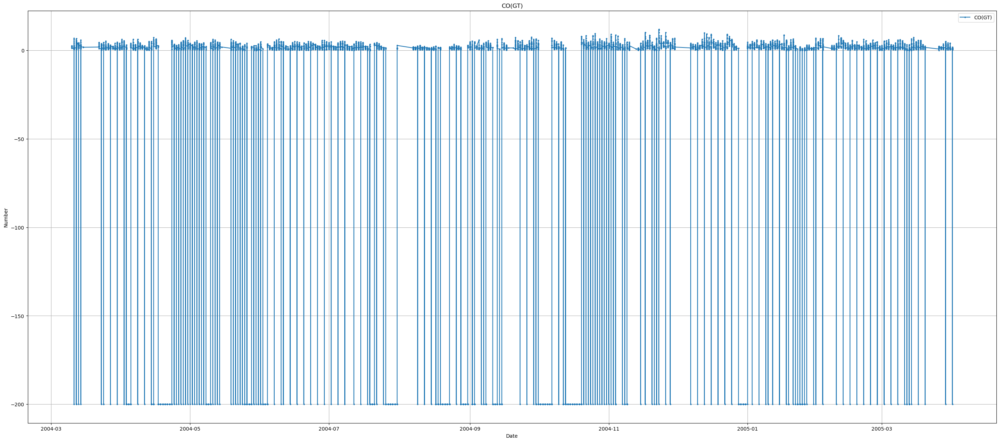

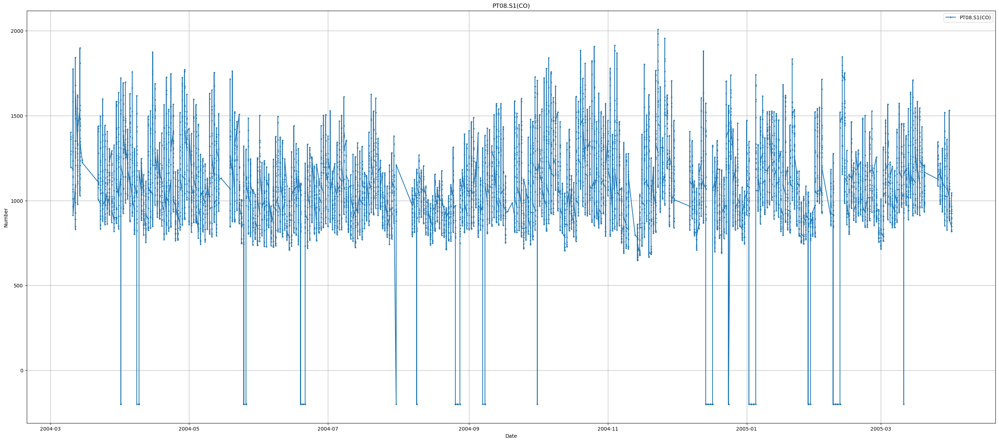

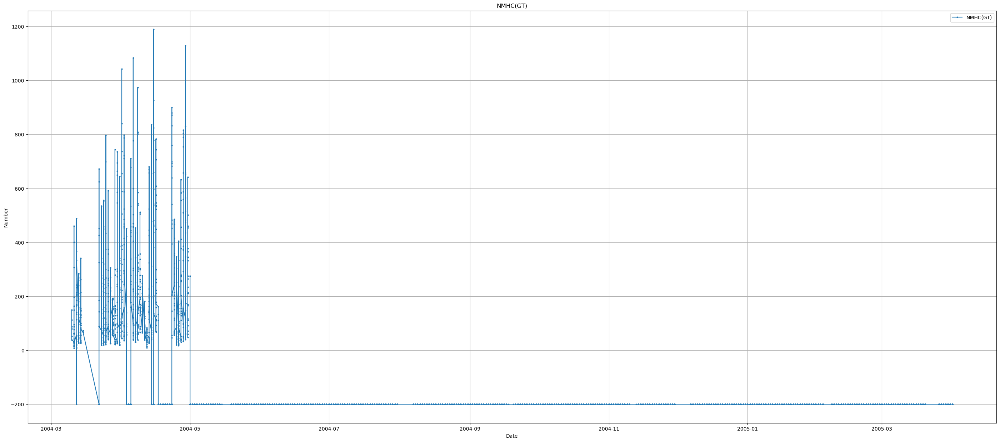

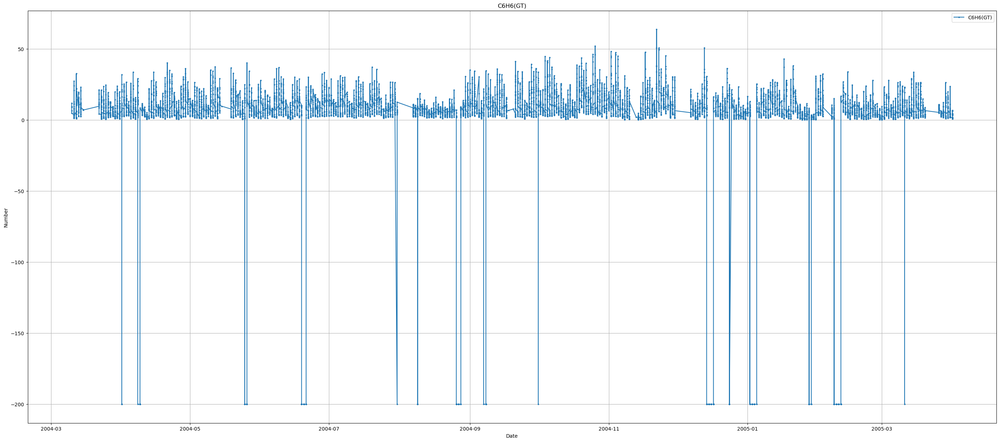

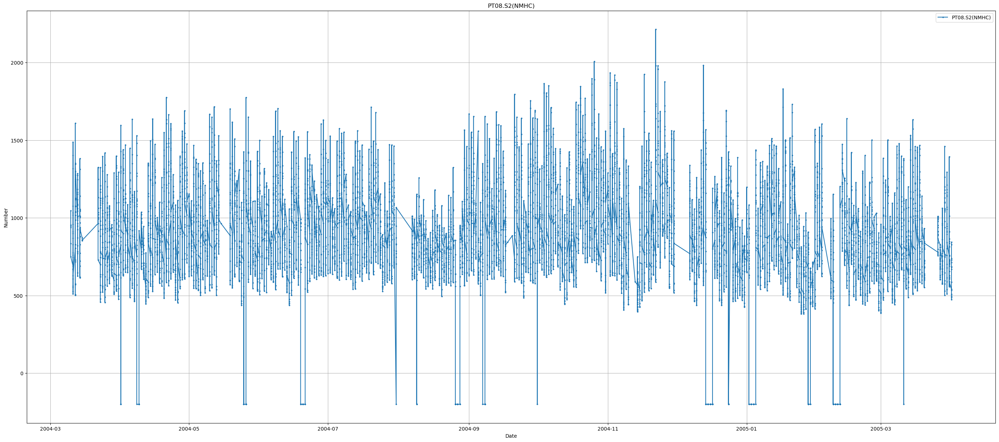

...

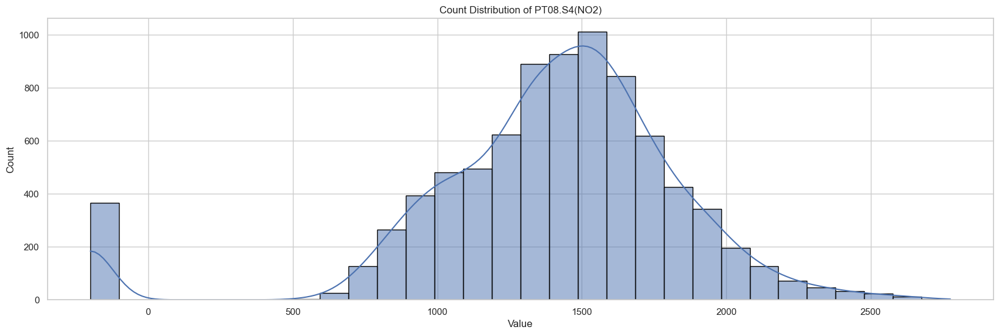

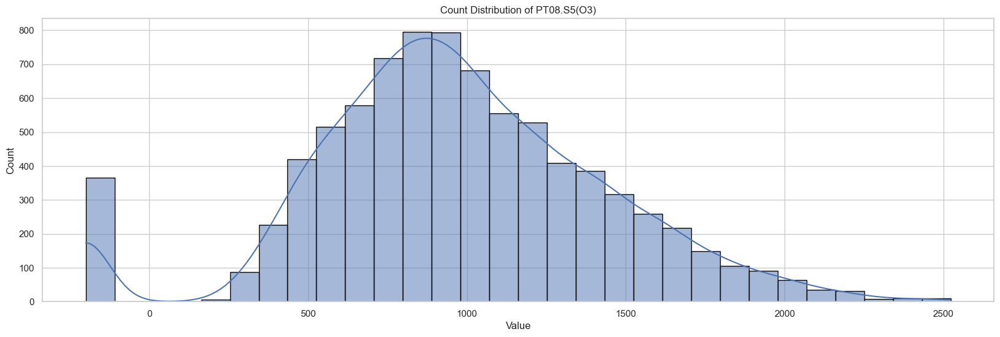

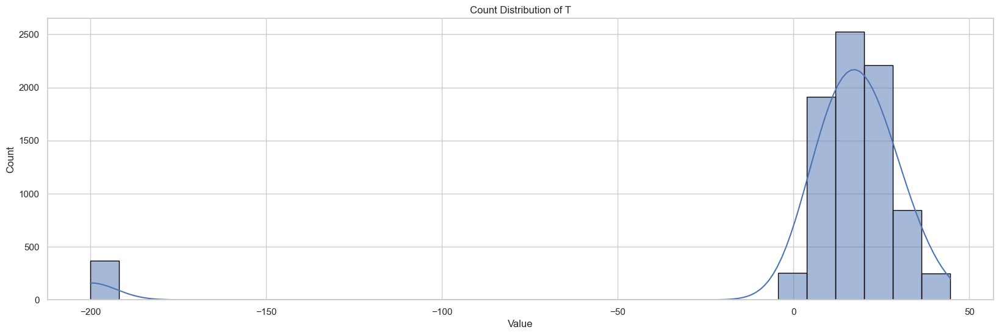

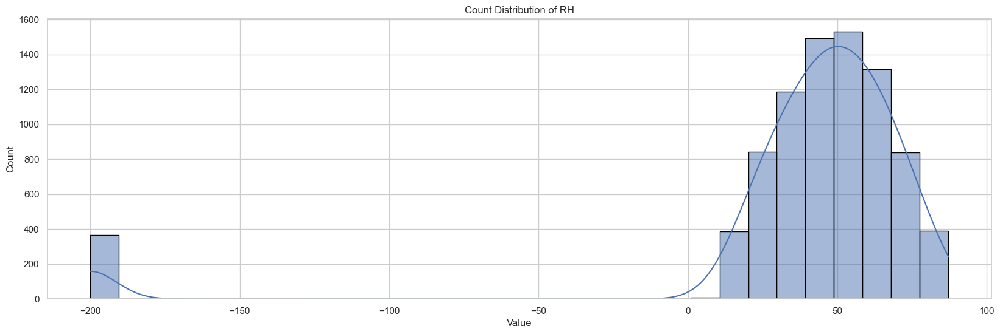

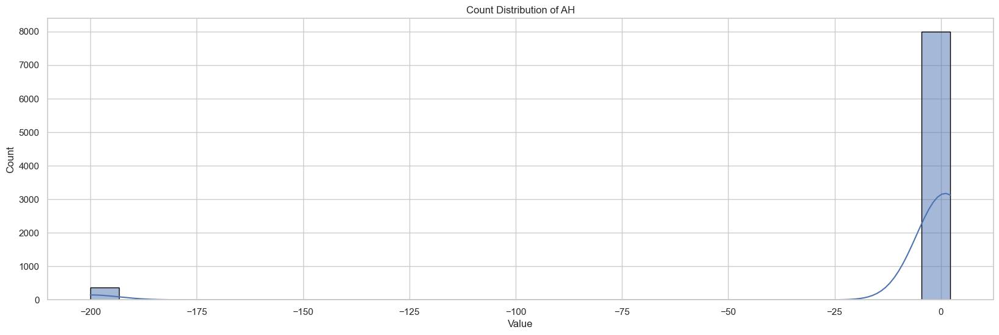


The numbers of missing values in columns:
CO(GT)           1585
PT08.S1(CO)       366
NMHC(GT)         7525
C6H6(GT)          366
PT08.S2(NMHC)     366
NOx(GT)          1573
PT08.S3(NOx)      366
NO2(GT)          1576
PT08.S4(NO2)      366
PT08.S5(O3)       366
T                 366
RH                366
AH                366
dtype: int64


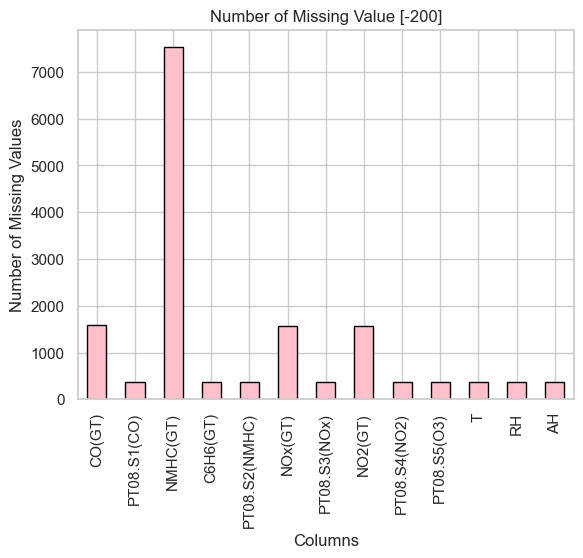

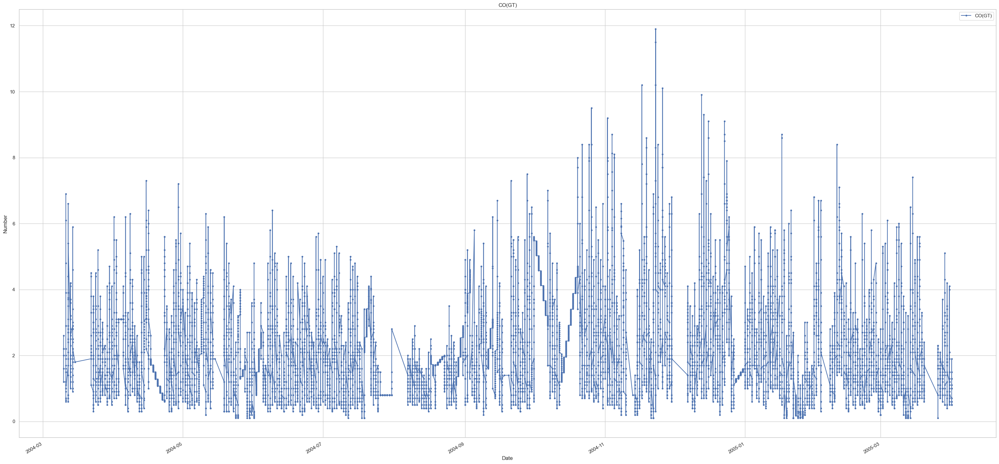

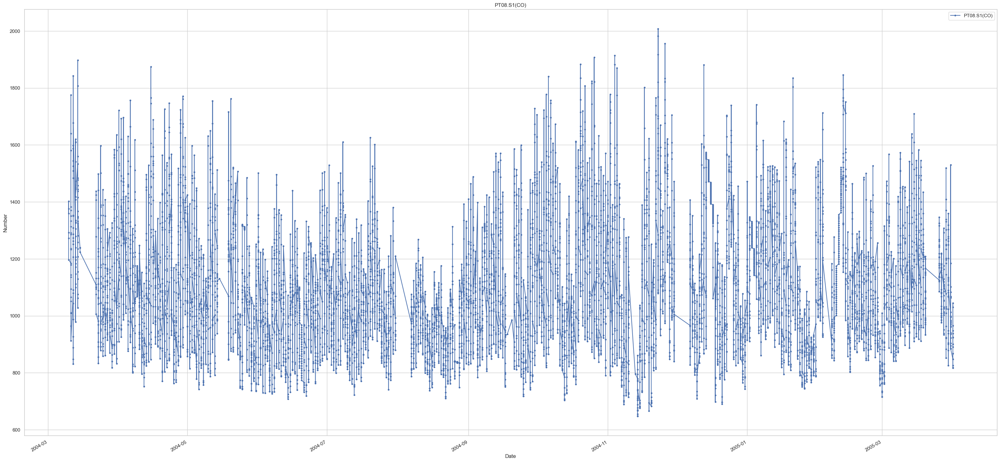

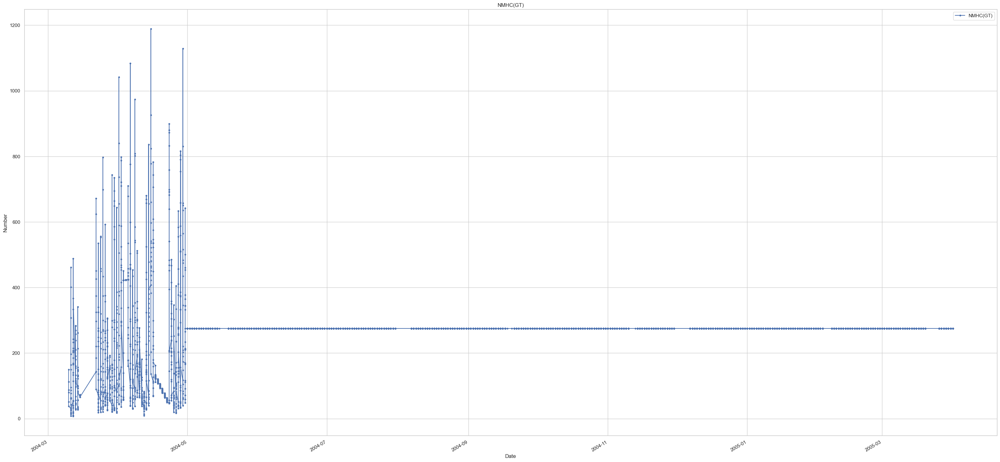

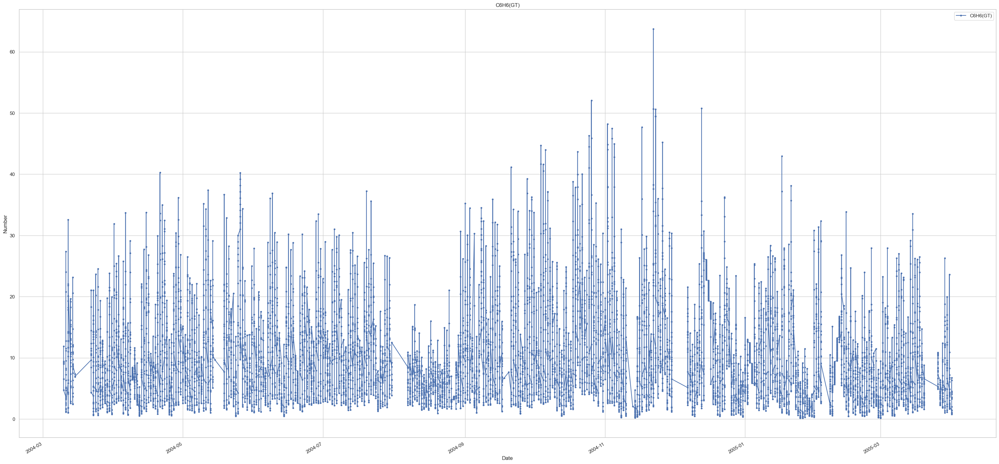

...

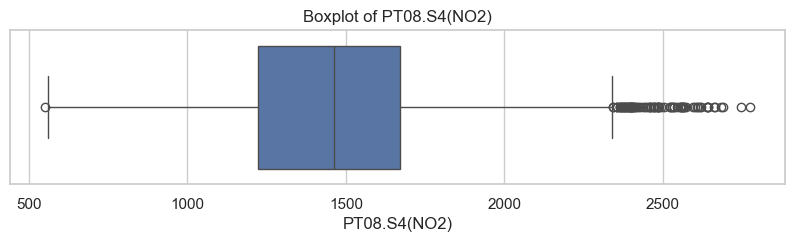

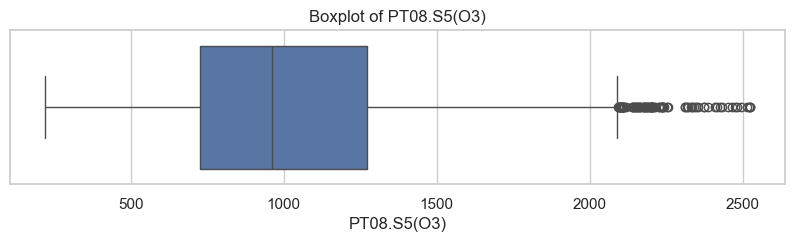

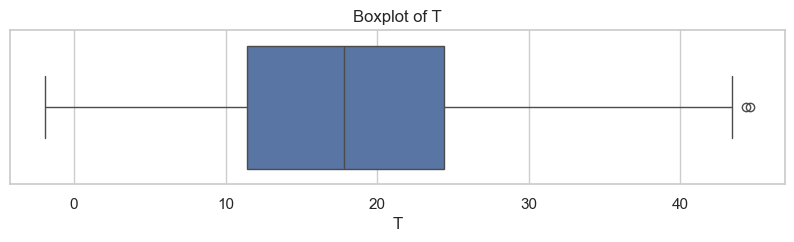

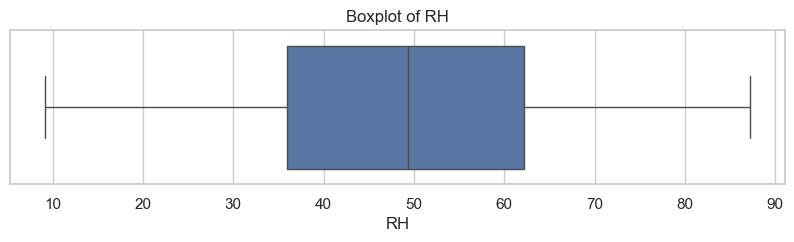

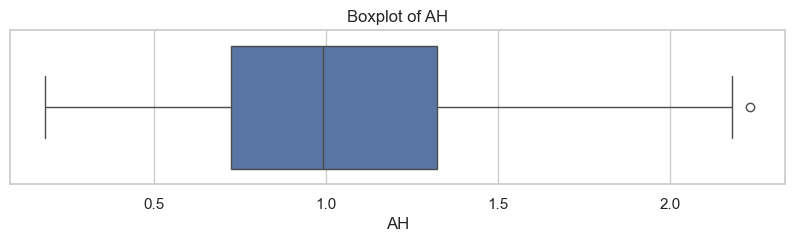


The mean of CO(GT) without missing value: 2.14
Epoch 1/100
 1/46 [..............................] - ETA: 7s - loss: 0.8007 - accuracy: 0.3750

2024-06-26 14:55:30.608508: W tensorflow/tsl/platform/profile_utils/cpu_utils.cc:128] Failed to get CPU frequency: 0 Hz


46/46 [==============================] - 0s 2ms/step - loss: 0.5356 - accuracy: 0.7545 - val_loss: 0.3535 - val_accuracy: 0.8876
Epoch 2/100
46/46 [==============================] - 0s 588us/step - loss: 0.3603 - accuracy: 0.8685 - val_loss: 0.2868 - val_accuracy: 0.8868
Epoch 3/100
46/46 [==============================] - 0s 590us/step - loss: 0.3288 - accuracy: 0.8742 - val_loss: 0.2745 - val_accuracy: 0.8868
Epoch 4/100
46/46 [==============================] - 0s 591us/step - loss: 0.3243 - accuracy: 0.8718 - val_loss: 0.2697 - val_accuracy: 0.8892
Epoch 5/100
46/46 [==============================] - 0s 589us/step - loss: 0.3159 - accuracy: 0.8768 - val_loss: 0.2665 - val_accuracy: 0.8939
Epoch 6/100
46/46 [==============================] - 0s 581us/step - loss: 0.3131 - accuracy: 0.8803 - val_loss: 0.2639 - val_accuracy: 0.8955
Epoch 7/100
46/46 [==============================] - 0s 588us/step - loss: 0.3082 - accuracy: 0.8771 - val_loss: 0.2616 - val_accuracy: 0.8963
Epoch 8/100
4

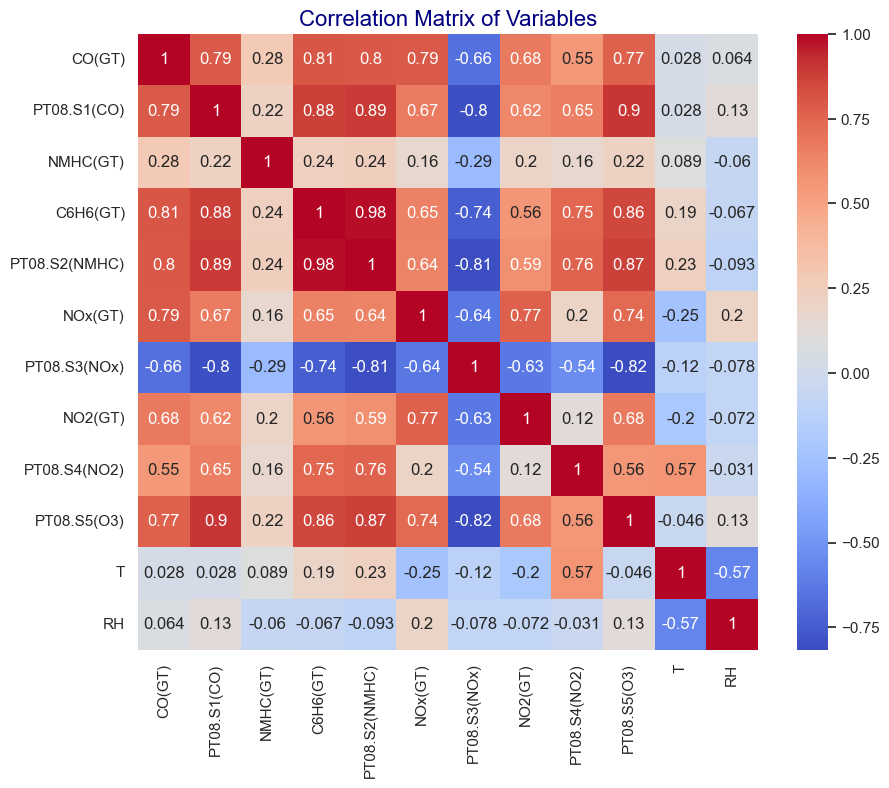

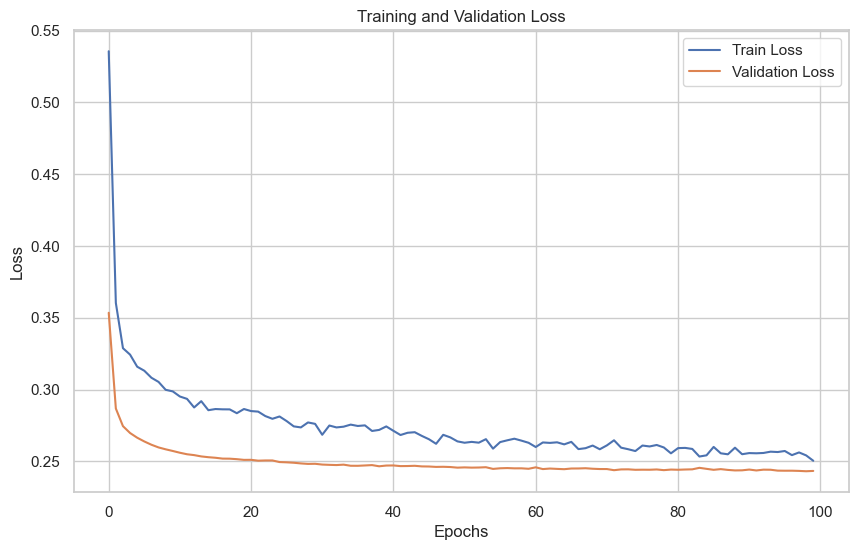

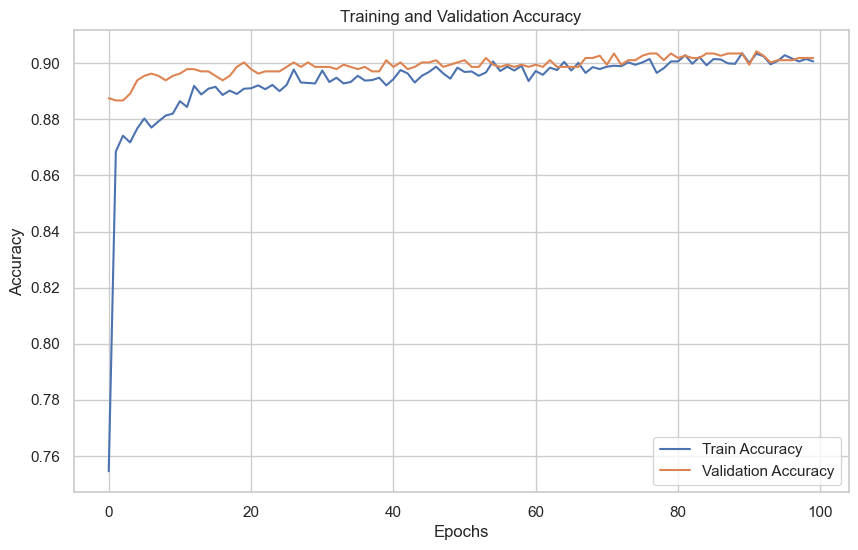

40/40 [==============================] - 0s 237us/step
Confusion Matrix:
[[669  54]
 [ 67 464]]
True Positive: 464
False Positive: 54
True Negative: 669
False Negative: 67


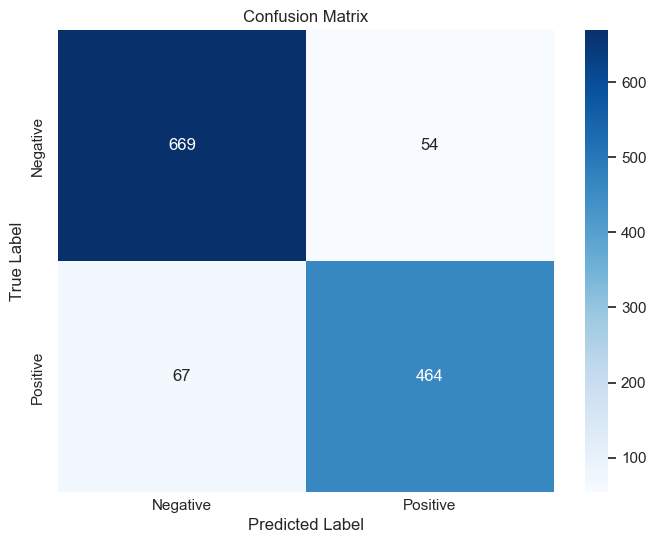

Accuracy: 0.90
Precision: 0.90

Epoch 1/100
183/183 [==============================] - 0s 656us/step - loss: 73054.6562 - mean_squared_error: 73054.3516 - val_loss: 173608.6250 - val_mean_squared_error: 173608.2500
Epoch 2/100
183/183 [==============================] - 0s 379us/step - loss: 55323.9805 - mean_squared_error: 55323.3359 - val_loss: 101902.2969 - val_mean_squared_error: 101901.3359
Epoch 3/100
183/183 [==============================] - 0s 365us/step - loss: 31082.8203 - mean_squared_error: 31081.6172 - val_loss: 53084.6250 - val_mean_squared_error: 53083.2500
Epoch 4/100
183/183 [==============================] - 0s 369us/step - loss: 26467.6895 - mean_squared_error: 26466.3223 - val_loss: 45594.0234 - val_mean_squared_error: 45592.6289
Epoch 5/100
183/183 [==============================] - 0s 369us/step - loss: 24906.9648 - mean_squared_error: 24905.5625 - val_loss: 38749.5625 - val_mean_squared_error: 38748.1289
Epoch 6/100
183/183 [==============================] - 0s 3

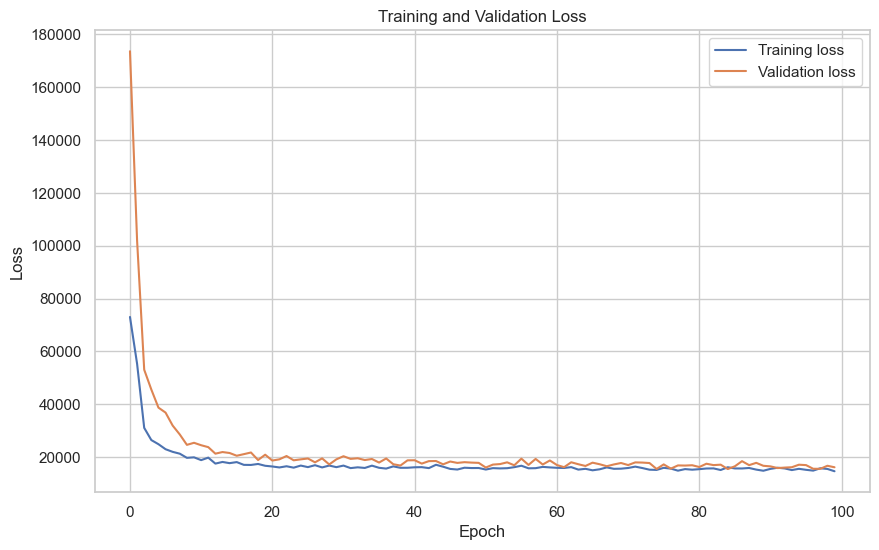

53/53 [==============================] - 0s 251us/step


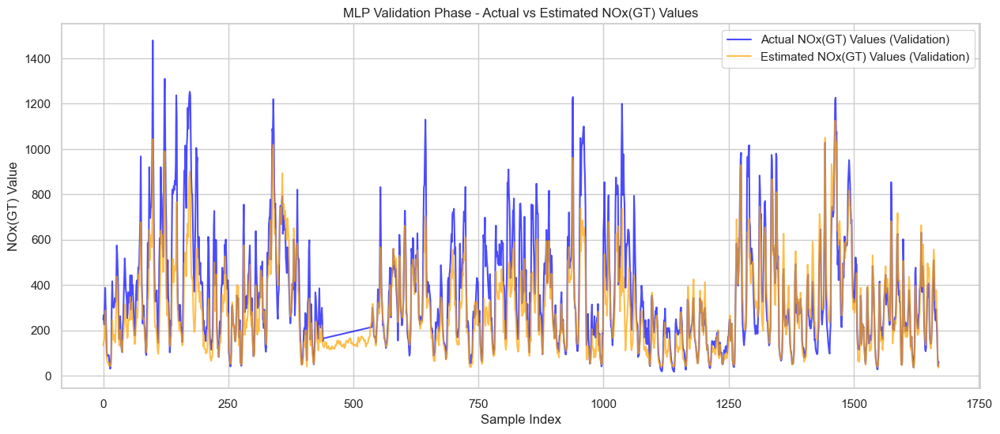

27/27 [==============================] - 0s 630us/step

RMSE (< 280): 78.41
MAE (< 220): 57.50
Number of samples: 837


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
from sklearn.metrics import mean_squared_error, mean_absolute_error
import joblib

def Regression(dataset):
    # 3.0 load data
    df = dataset
    
    # 3.1. Data processing
    # 3.1.1 Feature selection
    # Columns with correlation over 0.64, excluding 'NOx(GT)'
    columns_to_drop = ["Date", "Time", "NMHC(GT)", "NOx(GT)", "PT08.S3(NOx)", "PT08.S4(NO2)", "T", "RH", "AH", "CO_target"]
    x = df.drop(columns=columns_to_drop)
    y = df["NOx(GT)"]

    
    #  3.1.2 Normalisation
    scaler = StandardScaler()
    joblib.dump(scaler, 'Rscaler.pkl')
    X_scaled = scaler.fit_transform(x)

    # 3.1.3 Split data set
    # Split data set by time： 70% for training， 20% for validation， 10%for test 
    a = 0.7
    b = 0.2
    train_size = int(a * len(X_scaled))
    val_size = int(b * len(X_scaled))
    test_size = len(X_scaled) - train_size - val_size

    x_train_scaled = X_scaled[:train_size]
    y_train = y[:train_size]
    x_val_scaled = X_scaled[train_size:train_size + val_size]
    y_val = y[train_size:train_size + val_size]
    x_test_scaled = X_scaled[train_size + val_size:]
    y_test = y[train_size + val_size:]

    # 3.2 Build neural networks
    input_shape = x_train_scaled.shape[1]
    a, c, e =32,16, 1
    b, d = 0.4, 0.4
    lr = 0.001          # Learning rate
    
    model = Sequential([
        Input(shape=(input_shape,)),                                # Input layer
        Dense(a, activation="relu", kernel_regularizer=l2(0.01)),   # First dense layer has 32 nodes. activation function of ReLU is for increasing the nonlinearity of the model，applying L2 regularisation 
        Dropout(b),                                                 # First Dropout layer：dropout rate is 0.4 for reducing overfitting
        Dense(c, activation="relu",kernel_regularizer=l2(0.01)),    # Second Dense layer has 16 nodes. activation function of ReLU is for increasing the nonlinearity of the model，applying L2 regularisation 
        Dropout(d),                                                 # Second Dropout layer：dropout rate is 0.4 for reducing overfitting
        Dense(e, activation="linear")                               # Output layer： activation function of linear is for outputing continuous values
    ])
    
    model.compile(optimizer=Adam(learning_rate=lr), loss="mean_squared_error", metrics=["mean_squared_error"])
    # Mean_squared_error is used to minimise the error between predicted and true values


    # 3.3 Training
    history = model.fit(x_train_scaled, y_train, epochs=100, batch_size=32, validation_data=(x_val_scaled, y_val))
    # history= pd.DataFrame(history.history)
    model.save('regression_model.h5') 
    print()


    # 3.4 Result
    # 3.4.1 Visualisation of results
    # Line plot of 'Training and Validation Loss'
    plt.figure(figsize=(10, 6))
    plt.plot(history.history['loss'], label='Training loss')
    plt.plot(history.history['val_loss'], label='Validation loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.show()

    # 3.5 Model Evaluation
    # 3.5.1 Predictionusing validation sets
    predicted_values = model.predict(x_val_scaled).flatten()
    actual_values = y_val
    shift_indexes = np.arange(len(actual_values))  # Generate a sequence of integers for picture

    # 3.5.2 MLP Validation Phase
    plt.figure(figsize=(15, 6))
    plt.plot(np.arange(len(y_val)), y_val, label='Actual NOx(GT) Values (Validation)', color='blue', alpha=0.7)
    plt.plot(predicted_values, label='Estimated NOx(GT) Values (Validation)', color='orange', alpha=0.7)
    plt.title('MLP Validation Phase - Actual vs Estimated NOx(GT) Values')
    plt.xlabel('Sample Index')
    plt.ylabel('NOx(GT) Value')
    plt.legend()
    plt.show()

    # 3.5.3 Evaluation（RMSE and MAE）
    predicted_values_test = model.predict(x_test_scaled).flatten()
    rmse = np.sqrt(mean_squared_error(y_test, predicted_values_test))
    mae = mean_absolute_error(y_test, predicted_values_test)

    print()
    print(f"RMSE (< 280): {rmse:.2f}")
    print(f"MAE (< 220): {mae:.2f}")
    print(f"Number of samples: {len(y_test)}")


file_name = "AirQualityUCI _ Students.xlsx"
linear = Data_preprocessing(file_name)
print()
classification(linear)
print()
Regression(linear)

## 4. Script

### 4.1 Data preprocessing

In [4]:
from tensorflow.keras.models import load_model
classification_model = load_model('classification_model.h5')
regression_model = load_model('regression_model.h5')


# filename = ''
# new_data = pd.read_csv(filename)
new_data = pd.read_csv('newvalues_9414.csv')
columns_digit = new_data.columns[2:]
new_data[columns_digit] = new_data[columns_digit].replace(-200, np.nan)

new_data = new_data.infer_objects(copy=False)

time_column = new_data['Time']
date_column = new_data['Date']

new_data_numeric = new_data.drop(columns=['Time', 'Date'])

object_columns = new_data_numeric.select_dtypes(include=['object']).columns
for col in object_columns:
    new_data_numeric[col] = pd.to_numeric(new_data_numeric[col], errors='coerce')


linear_new = new_data_numeric.interpolate(method='linear', inplace=False)

linear_new['Time'] = time_column
linear_new['Date'] = date_column
linear_new = linear_new[['Date', 'Time'] + [col for col in linear_new.columns if col not in ['Date', 'Time']]]
linear_new

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,2004/3/11,15:00:00,2.20,1310.00,79.0,8.826223,932.50,184.0,1081.75,126.0,1646.50,946.25,8.325,79.799999,0.877784
1,2004/3/15,3:00:00,1.10,1078.25,44.0,4.429863,734.00,125.0,1128.25,98.5,1486.75,1020.50,12.600,63.474999,0.923017
2,2004/3/15,4:00:00,1.05,1077.50,44.0,3.995924,710.50,66.0,1150.00,71.0,1467.50,1012.75,12.350,65.350000,0.935112
3,2004/3/15,5:00:00,1.00,1074.50,39.0,3.865914,703.25,88.0,1155.75,74.0,1463.75,1010.00,11.900,67.449999,0.937538
4,2004/3/15,6:00:00,1.40,1156.75,51.0,6.385320,829.50,138.0,1029.50,80.0,1584.00,1083.00,11.375,70.525000,0.947516
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
994,2005/4/4,10:00:00,3.10,1314.25,143.0,13.529605,1101.25,471.7,538.50,189.8,1374.25,1728.50,21.850,29.250000,0.756824
995,2005/4/4,11:00:00,2.40,1162.50,143.0,11.355157,1027.00,353.3,603.75,179.2,1263.50,1269.00,24.325,23.725000,0.711864
996,2005/4/4,12:00:00,2.40,1142.00,143.0,12.374538,1062.50,293.0,603.25,174.7,1240.75,1092.00,26.900,18.350000,0.640649
997,2005/4/4,13:00:00,2.10,1002.50,143.0,9.547187,960.50,234.5,701.50,155.7,1041.00,769.75,28.325,13.550000,0.513866


### 4.2 Classification

In [5]:
from sklearn.preprocessing import StandardScaler

threholds = linear_new["CO(GT)"].mean()
linear_new["CO_target"] = (linear_new['CO(GT)'] >threholds).astype(int)
C_columns=["Date", "Time","CO(GT)", "NMHC(GT)","PT08.S3(NOx)","PT08.S4(NO2)","T","RH","AH","CO_target"]
c_x = linear_new.drop(columns=C_columns)
true_co_target = linear_new["CO_target"]

C_scaler = joblib.load('Cscaler.pkl')
new_data_scaled_c = C_scaler.fit_transform(c_x)

co_predictions = classification_model.predict(new_data_scaled_c)
co_predictions = (co_predictions > 0.5).astype(int)

accuracy = accuracy_score(true_co_target, co_predictions)
precision = precision_score(true_co_target, co_predictions, zero_division=1)
print(f"Accuracy: {accuracy:.2f}")
print(f"Precision: {precision:.2f}")

32/32 [==============================] - 0s 297us/step
Accuracy: 0.93
Precision: 0.93


### 4.3 Regression

In [6]:
R_column = ["Date", "Time", "NMHC(GT)","NOx(GT)","PT08.S3(NOx)","PT08.S4(NO2)","T","RH","AH", "CO_target"]
R_x = linear_new.drop(columns=R_column)
true_nox = linear_new["NOx(GT)"]
R_scaler = joblib.load('Rscaler.pkl')
new_data_scaled_R = R_scaler.fit_transform(R_x)
nox_predictions = regression_model.predict(new_data_scaled_R).flatten()

# RMSE和MAE
rmse = np.sqrt(mean_squared_error(true_nox, nox_predictions))
mae = mean_absolute_error(true_nox, nox_predictions)
print(f"RMSE (< 280): {rmse:.2f}")
print(f"MAE(< 220): {mae:.2f}")

32/32 [==============================] - 0s 308us/step
RMSE (< 280): 112.07
MAE(< 220): 73.90
